## Evaluating AgriCLIP + SAM2 on WeedsGalore CVF 2025

In [1]:
import os
import sys
import json
import time
import random
import zipfile
import shutil

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn.functional as F
from torchvision import transforms

from tqdm.auto import tqdm

In [2]:

#Paths registry 
PROJECT_ROOT = Path("/home/zahranadeem/thesis")

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

###############################################

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_attention_guided_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)


Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt


In [3]:
PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

WEEDSGALORE_ROOT = (
    PROJECT_ROOT / "WeedsGalore"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "weedsgalore_agriclip_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project:", PROJECT_ROOT)
print("WeedsGalore:", WEEDSGALORE_ROOT)
print("Output:", OUTPUT_DIR)

Project: /home/zahranadeem/thesis
WeedsGalore: /home/zahranadeem/thesis/WeedsGalore
Output: /home/zahranadeem/thesis/results/weedsgalore_agriclip_sam2


In [4]:
from pathlib import Path
import os

from huggingface_hub import snapshot_download

# GitHub repository
WEEDSGALORE_REPO = Path(
    "/home/zahranadeem/thesis/WeedsGalore"
)

# Actual dataset
WEEDSGALORE_ROOT = Path(
    "/home/zahranadeem/thesis/WeedsGalore_dataset"
)

WEEDSGALORE_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("GitHub repo:")
print(WEEDSGALORE_REPO)

print("\nDataset directory:")
print(WEEDSGALORE_ROOT)

print("\nDownloading WeedsGalore dataset...")

snapshot_download(
    repo_id="Voxel51/weeds-galore",
    repo_type="dataset",
    local_dir=str(WEEDSGALORE_ROOT),
    ignore_patterns=[
        ".git*",
        "README.md"
    ]
)

print("\nDownload complete.")

GitHub repo:
/home/zahranadeem/thesis/WeedsGalore

Dataset directory:
/home/zahranadeem/thesis/WeedsGalore_dataset



Fetching 473 files:   0%|          | 0/473 [00:00<?, ?it/s]


Download complete.


In [5]:
#Inspecting what was downloaded 
print("Top-level contents:\n")

for item in sorted(WEEDSGALORE_ROOT.iterdir()):
    print(item.name, "->", "DIR" if item.is_dir() else "FILE")

Top-level contents:

.cache -> DIR
data -> DIR
dataset_preview.png -> FILE
fields -> DIR
fiftyone.yml -> FILE
metadata.json -> FILE
samples.json -> FILE
weeds_galore.gif -> FILE


In [6]:
# Inspect directories up to 3 levels deep

for path in sorted(WEEDSGALORE_ROOT.rglob("*")):

    relative = path.relative_to(WEEDSGALORE_ROOT)

    if len(relative.parts) <= 3:
        print(relative)

.cache
.cache/huggingface
.cache/huggingface/.gitignore
.cache/huggingface/CACHEDIR.TAG
.cache/huggingface/download
data
data/2023-05-25_0109.png
data/2023-05-25_0114.png
data/2023-05-25_0119.png
data/2023-05-25_0147.png
data/2023-05-25_0150.png
data/2023-05-25_0158.png
data/2023-05-25_0170.png
data/2023-05-25_0183.png
data/2023-05-25_0189.png
data/2023-05-25_0219.png
data/2023-05-25_0222.png
data/2023-05-25_0228.png
data/2023-05-25_0363.png
data/2023-05-25_0379.png
data/2023-05-25_0383.png
data/2023-05-25_0402.png
data/2023-05-25_0406.png
data/2023-05-25_0416.png
data/2023-05-25_0463.png
data/2023-05-25_0468.png
data/2023-05-25_0473.png
data/2023-05-25_0476.png
data/2023-05-25_0486.png
data/2023-05-25_0500.png
data/2023-05-25_0640.png
data/2023-05-25_0670.png
data/2023-05-25_0672.png
data/2023-05-25_0681.png
data/2023-05-25_0685.png
data/2023-05-25_0695.png
data/2023-05-25_0740.png
data/2023-05-25_0743.png
data/2023-05-25_0750.png
data/2023-05-25_0776.png
data/2023-05-25_0780.png
data

In [7]:
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp",
}

all_images = [
    p
    for p in WEEDSGALORE_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in image_extensions
]

print("Total image-like files:", len(all_images))

from collections import Counter

extension_counts = Counter(
    p.suffix.lower()
    for p in all_images
)

print("\nExtensions:")
for ext, count in extension_counts.items():
    print(f"{ext}: {count}")

Total image-like files: 469

Extensions:
.png: 469


In [8]:
annotation_candidates = []

for p in WEEDSGALORE_ROOT.rglob("*"):

    if not p.is_file():
        continue

    name = p.name.lower()
    path_string = str(p).lower()

    if any(
        keyword in path_string
        for keyword in [
            "semantic",
            "semantics",
            "instance",
            "instances",
            "mask",
            "annotation",
            "label"
        ]
    ):
        annotation_candidates.append(p)

print(
    "Potential annotation files:",
    len(annotation_candidates)
)

for p in annotation_candidates[:100]:
    print(
        p.relative_to(WEEDSGALORE_ROOT)
    )

Potential annotation files: 312
fields/ground_truth_semantic/2023-06-06_0953.png
fields/ground_truth_semantic/2023-05-25_0966.png
fields/ground_truth_semantic/2023-05-25_0672.png
fields/ground_truth_semantic/2023-05-25_0486.png
fields/ground_truth_semantic/2023-06-15_0169.png
fields/ground_truth_semantic/2023-05-25_0379.png
fields/ground_truth_semantic/2023-06-15_0996.png
fields/ground_truth_semantic/2023-06-06_0680.png
fields/ground_truth_semantic/2023-05-30_0730.png
fields/ground_truth_semantic/2023-05-30_0720.png
fields/ground_truth_semantic/2023-06-06_0728.png
fields/ground_truth_semantic/2023-05-25_0383.png
fields/ground_truth_semantic/2023-05-25_0681.png
fields/ground_truth_semantic/2023-06-06_0736.png
fields/ground_truth_semantic/2023-05-30_0086.png
fields/ground_truth_semantic/2023-05-30_0915.png
fields/ground_truth_semantic/2023-05-30_0321.png
fields/ground_truth_semantic/2023-05-30_0114.png
fields/ground_truth_semantic/2023-05-25_0468.png
fields/ground_truth_semantic/2023-05-

In [9]:
#Defining Weedsgalore masks 
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

WEEDSGALORE_ROOT = Path(
    "/home/zahranadeem/thesis/WeedsGalore_dataset"
)

WEEDS_IMAGE_DIR = (
    WEEDSGALORE_ROOT / "data"
)

WEEDS_MASK_DIR = (
    WEEDSGALORE_ROOT
    / "fields"
    / "ground_truth_semantic"
)

print("Images:", WEEDS_IMAGE_DIR)
print("Masks :", WEEDS_MASK_DIR)

print("Images exist:", WEEDS_IMAGE_DIR.exists())
print("Masks exist :", WEEDS_MASK_DIR.exists())

Images: /home/zahranadeem/thesis/WeedsGalore_dataset/data
Masks : /home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic
Images exist: True
Masks exist : True


In [10]:
#making image mask pairs 
image_files = sorted(
    WEEDS_IMAGE_DIR.glob("*.png")
)

mask_files = sorted(
    WEEDS_MASK_DIR.glob("*.png")
)

print("Images:", len(image_files))
print("Masks :", len(mask_files))

Images: 156
Masks : 156


In [11]:
#matching by mame 
mask_lookup = {
    p.name: p
    for p in mask_files
}

weeds_pairs = []

for image_path in image_files:

    mask_path = mask_lookup.get(
        image_path.name
    )

    if mask_path is not None:

        weeds_pairs.append({
            "image": image_path,
            "mask": mask_path,
        })

print(
    "Matched image-mask pairs:",
    len(weeds_pairs)
)

print("\nFirst 10 pairs:")

for pair in weeds_pairs[:10]:
    print(
        pair["image"].name,
        "<->",
        pair["mask"].name
    )

Matched image-mask pairs: 156

First 10 pairs:
2023-05-25_0109.png <-> 2023-05-25_0109.png
2023-05-25_0114.png <-> 2023-05-25_0114.png
2023-05-25_0119.png <-> 2023-05-25_0119.png
2023-05-25_0147.png <-> 2023-05-25_0147.png
2023-05-25_0150.png <-> 2023-05-25_0150.png
2023-05-25_0158.png <-> 2023-05-25_0158.png
2023-05-25_0170.png <-> 2023-05-25_0170.png
2023-05-25_0183.png <-> 2023-05-25_0183.png
2023-05-25_0189.png <-> 2023-05-25_0189.png
2023-05-25_0219.png <-> 2023-05-25_0219.png


In [12]:
#inspect 1 pair 
sample = weeds_pairs[0]

image = Image.open(
    sample["image"]
).convert("RGB")

mask = np.array(
    Image.open(sample["mask"])
)

print("Image:", sample["image"])
print("Mask :", sample["mask"])

print("Image size:", image.size)
print("Mask shape:", mask.shape)

print(
    "Mask unique values:",
    np.unique(mask)
)

Image: /home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-05-25_0109.png
Mask : /home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-05-25_0109.png
Image size: (600, 600)
Mask shape: (600, 600)
Mask unique values: [0 1 3 5]


In [13]:
#Convert semantuc mask to binary vegetation 
unique_values, counts = np.unique(
    mask,
    return_counts=True
)

print("Mask classes:")

for value, count in zip(
    unique_values,
    counts
):
    print(
        f"Class {value}: {count} pixels"
    )


Mask classes:
Class 0: 359025 pixels
Class 1: 468 pixels
Class 3: 278 pixels
Class 5: 229 pixels


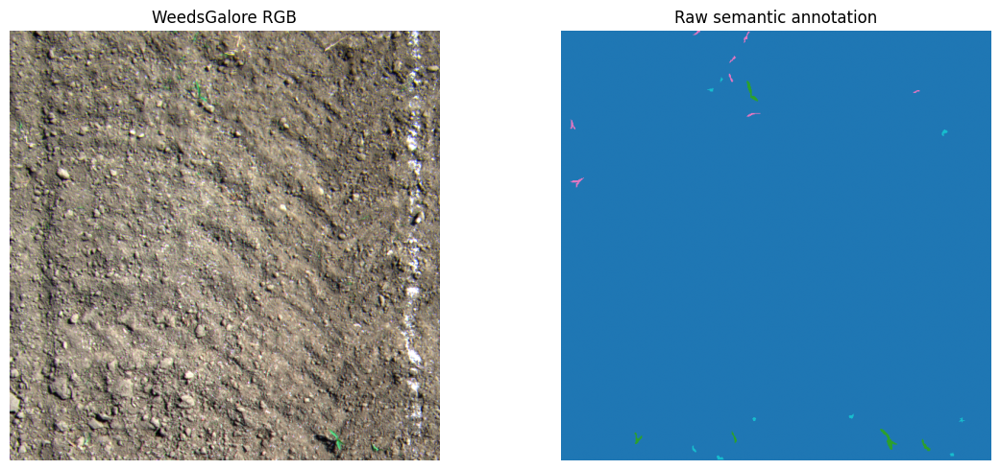

In [14]:
fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

ax[0].imshow(image)
ax[0].set_title("WeedsGalore RGB")
ax[0].axis("off")

ax[1].imshow(
    mask,
    cmap="tab10"
)
ax[1].set_title("Raw semantic annotation")
ax[1].axis("off")

plt.tight_layout()
plt.show()

In [15]:
#checking whether image/mask dimensions match 
dimension_mismatches = []

for pair in weeds_pairs:

    img = Image.open(
        pair["image"]
    )

    msk = Image.open(
        pair["mask"]
    )

    if img.size != msk.size:

        dimension_mismatches.append({
            "image": pair["image"].name,
            "image_size": img.size,
            "mask_size": msk.size,
        })

print(
    "Dimension mismatches:",
    len(dimension_mismatches)
)

if dimension_mismatches:
    for item in dimension_mismatches[:10]:
        print(item)

Dimension mismatches: 0


In [16]:
#define the loader 
def get_weeds_image(index):

    pair = weeds_pairs[index]

    image = Image.open(
        pair["image"]
    ).convert("RGB")

    return image


def get_weeds_mask(index):

    pair = weeds_pairs[index]

    mask = np.array(
        Image.open(pair["mask"])
    )

    # TEMPORARY:
    # assuming all non-zero classes are foreground.
    # We will change this if Cell 8 shows
    # specific class IDs need to be selected.

    mask = (
        mask > 0
    ).astype(np.uint8)

    return mask

In [17]:
#Test loader 
test_image = get_weeds_image(0)

test_mask = get_weeds_mask(0)

print(
    "Image size:",
    test_image.size
)

print(
    "Mask shape:",
    test_mask.shape
)

print(
    "Mask values:",
    np.unique(test_mask)
)

print(
    "Foreground pixels:",
    test_mask.sum()
)

Image size: (600, 600)
Mask shape: (600, 600)
Mask values: [0 1]
Foreground pixels: 975


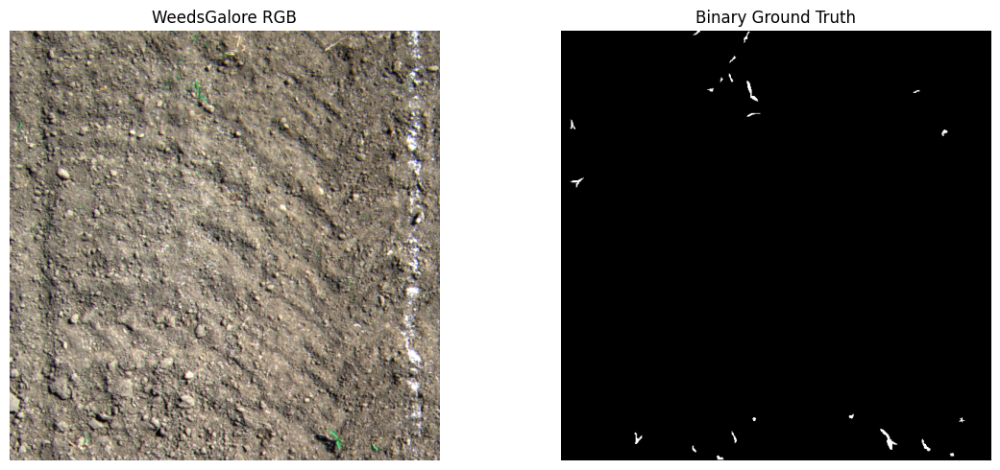

In [18]:
#Visualize binary GT 
fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

ax[0].imshow(test_image)
ax[0].set_title(
    "WeedsGalore RGB"
)
ax[0].axis("off")

ax[1].imshow(
    test_mask,
    cmap="gray"
)
ax[1].set_title(
    "Binary Ground Truth"
)
ax[1].axis("off")

plt.tight_layout()
plt.show()

In [19]:
#Device 
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )



Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [20]:
#DINO preprocessing 
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    ),
])

In [21]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")
print(
    "Parameters:",
    sum(
        p.numel()
        for p in dino_model.parameters()
    )
)

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO loaded.
Parameters: 23508032


In [22]:
import torch

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model = dino_model.to(device)
dino_model.eval()

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

Device: cuda
DINO loaded.


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


In [23]:
#Import Agriclip modules
print(
    "TextToConcept:",
    (
        ALIGNMENT_DIR /
        "TextToConcept.py"
    ).exists()
)

print(
    "LinearAligner:",
    (
        ALIGNMENT_DIR /
        "LinearAligner.py"
    ).exists()
)

TextToConcept: True
LinearAligner: True


In [24]:
if str(ALIGNMENT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(ALIGNMENT_DIR)
    )

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print(
    "AgriCLIP modules imported successfully."
)

AgriCLIP modules imported successfully.


In [25]:
#Initializing AgriCLIP textToConcepr 
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = (
    text_to_concept.linear_aligner
)

print(
    "VegAnn-trained aligner loaded."
)

print(
    "W shape:",
    tuple(aligner.W.shape)
)

print(
    "b shape:",
    tuple(aligner.b.shape)
)

VegAnn-trained aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [26]:
#DINO layer 4 hook 
captured_feature_map = None


def capture_layer4_output(
    module,
    inputs,
    output
):

    global captured_feature_map

    captured_feature_map = (
        output.detach()
    )


hook_handle = (
    dino_model.layer4.register_forward_hook(
        capture_layer4_output
    )
)

print(
    "DINO layer4 hook registered."
)

DINO layer4 hook registered.


In [27]:
@torch.no_grad()
def extract_dino_patch_features(
    pil_image
):

    global captured_feature_map

    captured_feature_map = None

    image_tensor = (
        dino_transform(
            pil_image
        )
        .unsqueeze(0)
        .to(device)
    )

    _ = dino_model(
        image_tensor
    )

    if captured_feature_map is None:
        raise RuntimeError(
            "Layer4 hook did not capture features."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map "
            "with shape (B,C,H,W), got "
            f"{captured_feature_map.shape}"
        )

    _, channels, grid_h, grid_w = (
        captured_feature_map.shape
    )

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(
            grid_h * grid_w,
            channels
        )
        .contiguous()
    )

    return (
        patch_features,
        grid_h,
        grid_w
    )

In [28]:
#Projecting in AgriCLIP concept space 
@torch.no_grad()
def align_patch_features(
    patch_features
):

    patch_features = (
        patch_features
        .float()
        .to(device)
    )

    aligned_features = (
        aligner.get_aligned_representation(
            patch_features
        )
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1
    )

    return aligned_features

In [29]:

    

# ============================================================
# PPOSITIVE / NEGATIVE
# ============================================================

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [30]:



# ============================================================
# ENCODE POSITIVE AND NEGATIVE PROMPT SETS
# ============================================================

@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)
# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])
Final vegetation embedding: torch.Size([512])


In [31]:
#generate AgriCLIP box 
@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k=32,
    margin=25
):

    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(
            image
        )
    )

    aligned_features = (
        align_patch_features(
            patch_features
        )
    )

    # Patch-to-text similarity
    scores = (
        aligned_features
        @ vegetation_embedding
    )

    scores_np = (
        scores.detach()
        .cpu()
        .numpy()
    )

    top_k = min(
        top_k,
        len(scores_np)
    )

    topk_indices = (
        np.argsort(
            scores_np
        )[::-1][:top_k]
    )

    image_width, image_height = (
        image.size
    )

    patch_width = (
        image_width / grid_w
    )

    patch_height = (
        image_height / grid_h
    )

    boxes = []

    for idx in topk_indices:

        row = (
            idx // grid_w
        )

        col = (
            idx % grid_w
        )

        x1 = int(
            col * patch_width
        )

        y1 = int(
            row * patch_height
        )

        x2 = int(
            (col + 1)
            * patch_width
        )

        y2 = int(
            (row + 1)
            * patch_height
        )

        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )

    boxes = np.array(
        boxes,
        dtype=np.int32
    )

    # Merge top-K patches
    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()

    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()

    # Add margin
    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        image_width - 1,
        xmax + margin
    )

    ymax = min(
        image_height - 1,
        ymax + margin
    )

    agriclip_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )

    return (
        agriclip_box,
        boxes,
        scores_np,
        topk_indices
    )

In [32]:
#Load SAM2 
from transformers import (
    Sam2Model,
    Sam2Processor,
)

sam2_processor = (
    Sam2Processor.from_pretrained(
        MODEL_NAME
    )
)

sam2_model = (
    Sam2Model.from_pretrained(
        MODEL_NAME
    )
)

print(
    "SAM2 loaded."
)



[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 loaded.


In [33]:
sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu"
)

print(
    "Checkpoint type:",
    type(sam2_checkpoint)
)

if (
    isinstance(
        sam2_checkpoint,
        dict
    )
    and
    "mask_decoder_state_dict"
    in sam2_checkpoint
):

    mask_decoder_state_dict = (
        sam2_checkpoint[
            "mask_decoder_state_dict"
        ]
    )

elif isinstance(
    sam2_checkpoint,
    dict
):

    mask_decoder_state_dict = (
        sam2_checkpoint
    )

else:

    raise TypeError(
        "Unsupported checkpoint structure."
    )

load_result = (
    sam2_model.mask_decoder
    .load_state_dict(
        mask_decoder_state_dict,
        strict=True
    )
)

sam2_model = (
    sam2_model
    .to(device)
)

sam2_model.eval()

print(
    "Fine-tuned SAM2 decoder loaded."
)

print(load_result)

Checkpoint type: <class 'dict'>
Fine-tuned SAM2 decoder loaded.
<All keys matched successfully>


In [34]:
#Predict 
@torch.no_grad()
def sam2_predict_box(
    image,
    box,
    threshold=0.5
):

    sam2_inputs = (
        sam2_processor(
            images=image,
            input_boxes=[
                [box.tolist()]
            ],
            return_tensors="pt"
        )
    )

    sam2_inputs = {
        k: (
            v.to(device)
            if torch.is_tensor(v)
            else v
        )
        for k, v in sam2_inputs.items()
    }

    outputs = sam2_model(
        **sam2_inputs
    )

    best_candidate_index = int(
        outputs.iou_scores[
            0,
            0
        ].argmax().item()
    )

    logits = outputs.pred_masks[
        0,
        0,
        best_candidate_index
    ]

    probability = torch.sigmoid(
        logits
    )

    original_height = int(
        sam2_inputs[
            "original_sizes"
        ][0, 0].item()
    )

    original_width = int(
        sam2_inputs[
            "original_sizes"
        ][0, 1].item()
    )

    probability = F.interpolate(
        probability[None, None],
        size=(
            original_height,
            original_width
        ),
        mode="bilinear",
        align_corners=False
    )[0, 0]

    probability_np = (
        probability
        .detach()
        .cpu()
        .numpy()
    )

    pred_mask = (
        probability_np >= threshold
    ).astype(np.uint8)

    confidence = float(
        outputs.iou_scores[
            0,
            0,
            best_candidate_index
        ].item()
    )

    return (
        pred_mask,
        probability_np,
        confidence
    )

In [35]:
#Merics 
def compute_binary_metrics(
    prediction,
    ground_truth
):

    prediction = (
        prediction.astype(bool)
    )

    ground_truth = (
        ground_truth.astype(bool)
    )

    intersection = np.logical_and(
        prediction,
        ground_truth
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth
    ).sum()

    pred_pixels = (
        prediction.sum()
    )

    gt_pixels = (
        ground_truth.sum()
    )

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice_denominator = (
        pred_pixels + gt_pixels
    )

    dice = (
        2.0 * intersection
        / dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "intersection": int(
            intersection
        ),
        "union": int(union),
        "pred_pixels": int(
            pred_pixels
        ),
        "gt_pixels": int(
            gt_pixels
        )
    }

In [36]:
# Testing complete pipeline on 1 WeedsGalore image

sample_index = 0

# Load image
image = get_weeds_image(
    sample_index
)

# Load ground-truth mask
gt_mask = get_weeds_mask(
    sample_index
)

print("Image size:", image.size)
print("GT mask shape:", gt_mask.shape)
print("GT mask values:", np.unique(gt_mask))
print("GT foreground pixels:", gt_mask.sum())


# --------------------------------------------------
# 1. Generate AgriCLIP box
# --------------------------------------------------

(
    agriclip_box,
    boxes,
    scores,
    topk_indices
) = generate_agriclip_box(
    image,
    top_k=32,
    margin=25
)

print("\nAgriCLIP box:")
print(agriclip_box)

print("\nTop-K patch indices:")
print(topk_indices)

print("\nTop-K scores:")
print(scores[topk_indices])


# --------------------------------------------------
# 2. SAM2 prediction using AgriCLIP box
# --------------------------------------------------

(
    pred_mask,
    probability,
    confidence
) = sam2_predict_box(
    image,
    agriclip_box,
    threshold=0.5
)

print("\nPrediction shape:", pred_mask.shape)
print("SAM2 confidence:", confidence)


# --------------------------------------------------
# 3. Compute metrics
# --------------------------------------------------

weeds_metrics = compute_binary_metrics(
    pred_mask,
    gt_mask
)


# --------------------------------------------------
# 4. Print metrics
# --------------------------------------------------

print("\n========== WEEDSGALORE RESULTS ==========")

for name, value in weeds_metrics.items():

    if isinstance(value, float):

        print(
            f"{name:>15}: "
            f"{value:.4f}"
        )

    else:

        print(
            f"{name:>15}: "
            f"{value}"
        )

Image size: (600, 600)
GT mask shape: (600, 600)
GT mask values: [0 1]
GT foreground pixels: 975

AgriCLIP box:
[  0   0 599 599]

Top-K patch indices:
[45 39 44 30 28 35 36 21 38 29 47 33 46 40  2  4 37 22  5 34 16 42  1 24
 23 18 43 19 26 41 12  3]

Top-K scores:
[0.09784081 0.0954994  0.09305528 0.08960826 0.08097823 0.0783546
 0.07734781 0.07728639 0.07647942 0.07587244 0.07438941 0.07343375
 0.07192312 0.07184113 0.06954258 0.06708052 0.06509738 0.06509191
 0.06506444 0.06345683 0.06268221 0.06170922 0.05979073 0.05955926
 0.05767942 0.05731167 0.05721691 0.0567603  0.05491035 0.0535851
 0.05329446 0.05286486]

Prediction shape: (600, 600)
SAM2 confidence: 0.8105747699737549

========== WEEDSGALORE RESULTS ==========
            iou: 0.2526
           dice: 0.4033
      precision: 0.6218
         recall: 0.2985
   intersection: 291
          union: 1152
    pred_pixels: 468
      gt_pixels: 975


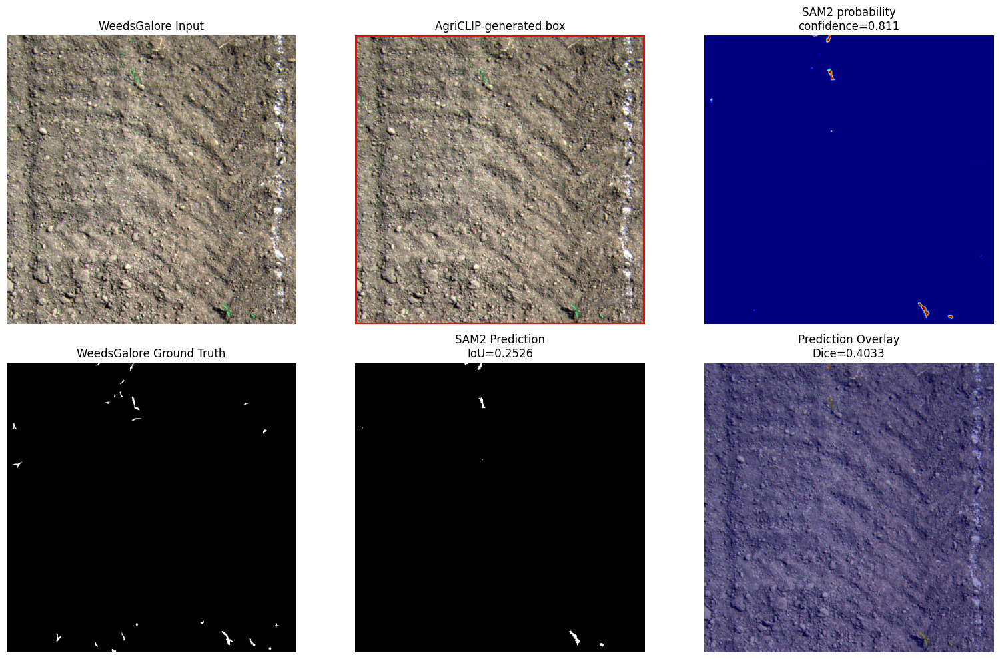

In [37]:
# Visualize WeedsGalore result

fig, ax = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)

# --------------------------------------------------
# Input image
# --------------------------------------------------

ax[0, 0].imshow(image)

ax[0, 0].set_title(
    "WeedsGalore Input"
)

ax[0, 0].axis("off")


# --------------------------------------------------
# AgriCLIP-generated box
# --------------------------------------------------

ax[0, 1].imshow(image)

x1, y1, x2, y2 = agriclip_box

ax[0, 1].add_patch(
    plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=3
    )
)

ax[0, 1].set_title(
    "AgriCLIP-generated box"
)

ax[0, 1].axis("off")


# --------------------------------------------------
# SAM2 probability
# --------------------------------------------------

ax[0, 2].imshow(
    probability,
    cmap="jet"
)

ax[0, 2].set_title(
    f"SAM2 probability\n"
    f"confidence={confidence:.3f}"
)

ax[0, 2].axis("off")


# --------------------------------------------------
# Ground truth
# --------------------------------------------------

ax[1, 0].imshow(
    gt_mask,
    cmap="gray"
)

ax[1, 0].set_title(
    "WeedsGalore Ground Truth"
)

ax[1, 0].axis("off")


# --------------------------------------------------
# Prediction
# --------------------------------------------------

ax[1, 1].imshow(
    pred_mask,
    cmap="gray"
)

ax[1, 1].set_title(
    f"SAM2 Prediction\n"
    f"IoU={weeds_metrics['iou']:.4f}"
)

ax[1, 1].axis("off")


# --------------------------------------------------
# Overlay
# --------------------------------------------------

ax[1, 2].imshow(image)

ax[1, 2].imshow(
    pred_mask,
    cmap="jet",
    alpha=0.40
)

ax[1, 2].set_title(
    f"Prediction Overlay\n"
    f"Dice={weeds_metrics['dice']:.4f}"
)

ax[1, 2].axis("off")


plt.tight_layout()
plt.show()

In [38]:
print("Total WeedsGalore pairs:", len(weeds_pairs))

Total WeedsGalore pairs: 156


In [39]:
import pandas as pd
import time
from tqdm.auto import tqdm

weeds_results = []

start_time = time.time()

for idx in tqdm(
    range(len(weeds_pairs)),
    desc="Evaluating WeedsGalore"
):

    try:

        # ------------------------------------------
        # 1. Load image and GT mask
        # ------------------------------------------

        image = get_weeds_image(idx)

        gt_mask = get_weeds_mask(idx)


        # ------------------------------------------
        # 2. Generate AgriCLIP box
        # ------------------------------------------

        (
            agriclip_box,
            boxes,
            scores,
            topk_indices
        ) = generate_agriclip_box(
            image,
            top_k=32,
            margin=25
        )


        # ------------------------------------------
        # 3. SAM2 prediction
        # ------------------------------------------

        (
            pred_mask,
            probability,
            confidence
        ) = sam2_predict_box(
            image,
            agriclip_box,
            threshold=0.5
        )


        # ------------------------------------------
        # 4. Compute metrics
        # ------------------------------------------

        metrics = compute_binary_metrics(
            pred_mask,
            gt_mask
        )


        # ------------------------------------------
        # 5. Store results
        # ------------------------------------------

        pair = weeds_pairs[idx]

        weeds_results.append({

            "image_id": idx,

            "file_name": Path(
                pair["image"]
            ).name,

            "iou": metrics["iou"],

            "dice": metrics["dice"],

            "precision": metrics["precision"],

            "recall": metrics["recall"],

            "sam2_confidence": float(
                confidence
            ),

            "box_x1": int(
                agriclip_box[0]
            ),

            "box_y1": int(
                agriclip_box[1]
            ),

            "box_x2": int(
                agriclip_box[2]
            ),

            "box_y2": int(
                agriclip_box[3]
            ),

        })


    except Exception as e:

        print(
            f"\nERROR at index {idx}: {e}"
        )

        continue


elapsed = (
    time.time() - start_time
)

print(
    f"\nEvaluation completed in "
    f"{elapsed / 60:.2f} minutes."
)

print(
    "Successful samples:",
    len(weeds_results)
)

print(
    "Failed samples:",
    len(weeds_pairs) - len(weeds_results)
)

Evaluating WeedsGalore:   0%|          | 0/156 [00:00<?, ?it/s]


Evaluation completed in 0.10 minutes.
Successful samples: 156
Failed samples: 0


In [40]:
weeds_df = pd.DataFrame(
    weeds_results
)

print(
    "Shape:",
    weeds_df.shape
)

print(
    weeds_df.head()
)

Shape: (156, 11)
   image_id            file_name       iou      dice  precision    recall  \
0         0  2023-05-25_0109.png  0.252604  0.403326   0.621795  0.298462   
1         1  2023-05-25_0114.png  0.533312  0.695634   0.713987  0.678202   
2         2  2023-05-25_0119.png  0.590956  0.742894   0.742411  0.743378   
3         3  2023-05-25_0147.png  0.391779  0.562990   0.627267  0.510662   
4         4  2023-05-25_0150.png  0.405367  0.576884   0.638251  0.526284   

   sam2_confidence  box_x1  box_y1  box_x2  box_y2  
0         0.810575       0       0     599     599  
1         0.763121       0       0     599     599  
2         0.798631       0       0     599     599  
3         0.750280       0       0     599     599  
4         0.815392       0       0     599     599  


In [41]:
weeds_mean_results = (
    weeds_df[
        [
            "iou",
            "dice",
            "precision",
            "recall",
            "sam2_confidence"
        ]
    ]
    .mean()
)

print(
    "Mean WeedsGalore Results"
)

print(
    weeds_mean_results
)

Mean WeedsGalore Results
iou                0.549908
dice               0.697754
precision          0.743147
recall             0.672999
sam2_confidence    0.864255
dtype: float64


In [42]:
weeds_percentage = (
    weeds_mean_results
    * 100
)

print(
    "========== PERCENTAGE RESULTS =========="
)

print(
    f"IoU       : {weeds_percentage['iou']:.2f}%"
)

print(
    f"Dice      : {weeds_percentage['dice']:.2f}%"
)

print(
    f"Precision : {weeds_percentage['precision']:.2f}%"
)

print(
    f"Recall    : {weeds_percentage['recall']:.2f}%"
)

print(
    f"Confidence: "
    f"{weeds_percentage['sam2_confidence']:.2f}%"
)

========== PERCENTAGE RESULTS ==========
IoU       : 54.99%
Dice      : 69.78%
Precision : 74.31%
Recall    : 67.30%
Confidence: 86.43%


In [43]:
WEEDSGALORE_RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "weedsgalore_agriclip_sam2"
)

WEEDSGALORE_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

results_csv = (
    WEEDSGALORE_RESULTS_DIR
    / "weedsgalore_results.csv"
)

weeds_df.to_csv(
    results_csv,
    index=False
)

print(
    "Saved:",
    results_csv
)


mean_csv = (
    WEEDSGALORE_RESULTS_DIR
    / "weedsgalore_mean_results.csv"
)

weeds_mean_results.to_frame(
    name="mean"
).to_csv(
    mean_csv
)

print(
    "Saved:",
    mean_csv
)

Saved: /home/zahranadeem/thesis/results/weedsgalore_agriclip_sam2/weedsgalore_results.csv
Saved: /home/zahranadeem/thesis/results/weedsgalore_agriclip_sam2/weedsgalore_mean_results.csv


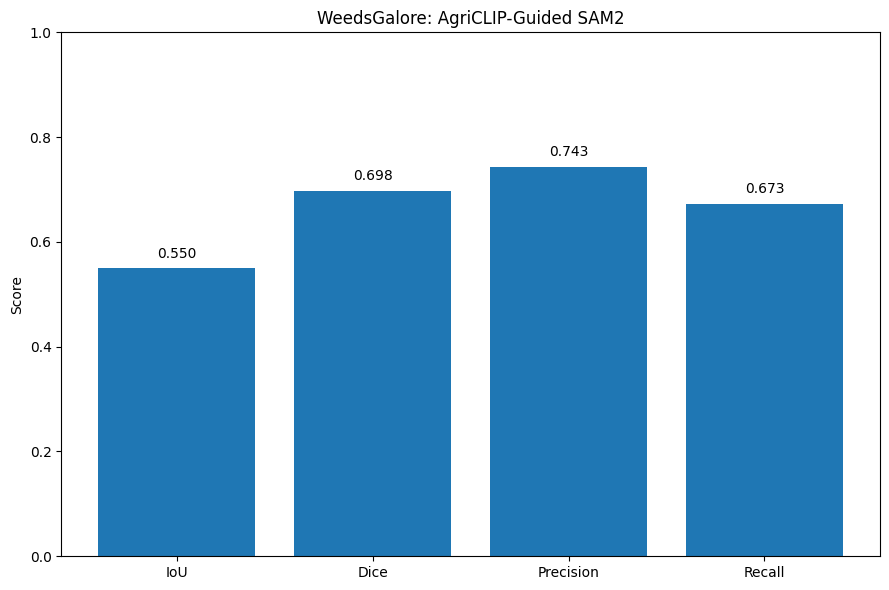

In [44]:
import matplotlib.pyplot as plt

metric_names = [
    "IoU",
    "Dice",
    "Precision",
    "Recall"
]

metric_values = [
    weeds_mean_results["iou"],
    weeds_mean_results["dice"],
    weeds_mean_results["precision"],
    weeds_mean_results["recall"]
]

plt.figure(
    figsize=(9, 6)
)

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Score"
)

plt.title(
    "WeedsGalore: AgriCLIP-Guided SAM2"
)

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.show()

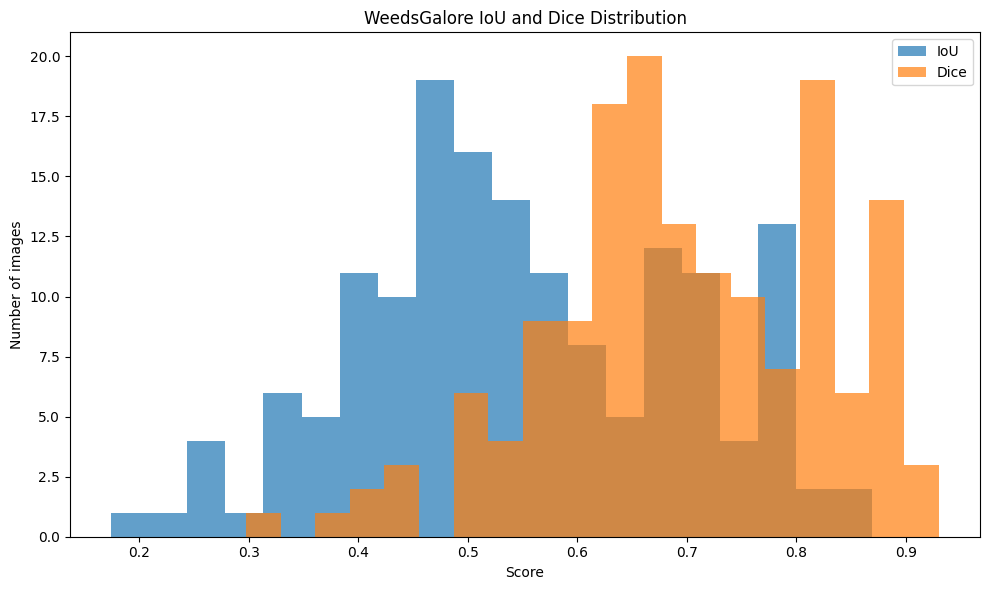

In [45]:
plt.figure(
    figsize=(10, 6)
)

plt.hist(
    weeds_df["iou"],
    bins=20,
    alpha=0.7,
    label="IoU"
)

plt.hist(
    weeds_df["dice"],
    bins=20,
    alpha=0.7,
    label="Dice"
)

plt.xlabel(
    "Score"
)

plt.ylabel(
    "Number of images"
)

plt.title(
    "WeedsGalore IoU and Dice Distribution"
)

plt.legend()

plt.tight_layout()

plt.show()

In [46]:
print("========== BEST 5 IMAGES ==========")

print(
    weeds_df[
        [
            "image_id",
            "file_name",
            "iou",
            "dice"
        ]
    ]
    .sort_values(
        "iou",
        ascending=False
    )
    .head(5)
)


print("\n========== WORST 5 IMAGES ==========")

print(
    weeds_df[
        [
            "image_id",
            "file_name",
            "iou",
            "dice"
        ]
    ]
    .sort_values(
        "iou",
        ascending=True
    )
    .head(5)
)

========== BEST 5 IMAGES ==========
     image_id            file_name       iou      dice
151       151  2023-06-15_0735.png  0.868871  0.929835
152       152  2023-06-15_0763.png  0.858348  0.923775
149       149  2023-06-15_0472.png  0.816091  0.898734
129       129  2023-06-06_0760.png  0.803254  0.890894
123       123  2023-06-06_0667.png  0.796192  0.886533

========== WORST 5 IMAGES ==========
    image_id            file_name       iou      dice
5          5  2023-05-25_0158.png  0.174785  0.297561
48        48  2023-05-30_0039.png  0.225038  0.367398
54        54  2023-05-30_0099.png  0.250055  0.400070
0          0  2023-05-25_0109.png  0.252604  0.403326
21        21  2023-05-25_0476.png  0.271594  0.427171


Best image index: 151


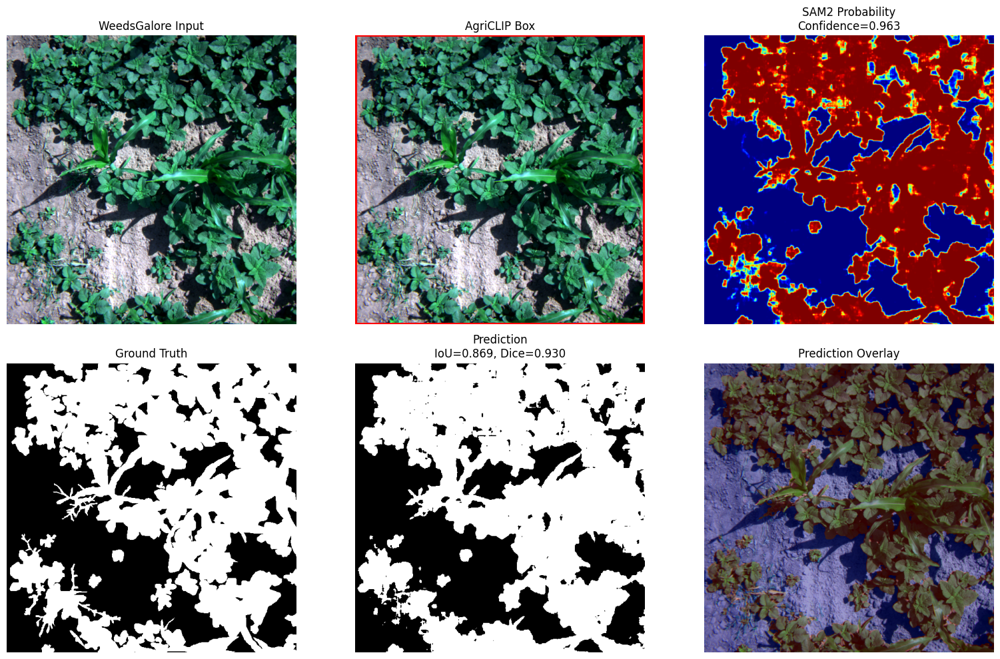

In [47]:
best_idx = int(
    weeds_df
    .sort_values(
        "iou",
        ascending=False
    )
    .iloc[0]["image_id"]
)

print(
    "Best image index:",
    best_idx
)

image = get_weeds_image(
    best_idx
)

gt_mask = get_weeds_mask(
    best_idx
)

(
    agriclip_box,
    boxes,
    scores,
    topk_indices
) = generate_agriclip_box(
    image,
    top_k=32,
    margin=25
)

(
    pred_mask,
    probability,
    confidence
) = sam2_predict_box(
    image,
    agriclip_box,
    threshold=0.5
)

best_metrics = compute_binary_metrics(
    pred_mask,
    gt_mask
)
fig, ax = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)

# Input
ax[0, 0].imshow(image)
ax[0, 0].set_title(
    "WeedsGalore Input"
)
ax[0, 0].axis("off")


# AgriCLIP box
ax[0, 1].imshow(image)

x1, y1, x2, y2 = agriclip_box

ax[0, 1].add_patch(
    plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=3
    )
)

ax[0, 1].set_title(
    "AgriCLIP Box"
)

ax[0, 1].axis("off")


# Probability
ax[0, 2].imshow(
    probability,
    cmap="jet"
)

ax[0, 2].set_title(
    f"SAM2 Probability\n"
    f"Confidence={confidence:.3f}"
)

ax[0, 2].axis("off")


# Ground truth
ax[1, 0].imshow(
    gt_mask,
    cmap="gray"
)

ax[1, 0].set_title(
    "Ground Truth"
)

ax[1, 0].axis("off")


# Prediction
ax[1, 1].imshow(
    pred_mask,
    cmap="gray"
)

ax[1, 1].set_title(
    f"Prediction\n"
    f"IoU={best_metrics['iou']:.3f}, "
    f"Dice={best_metrics['dice']:.3f}"
)

ax[1, 1].axis("off")


# Overlay
ax[1, 2].imshow(image)

ax[1, 2].imshow(
    pred_mask,
    cmap="jet",
    alpha=0.4
)

ax[1, 2].set_title(
    "Prediction Overlay"
)

ax[1, 2].axis("off")

plt.tight_layout()
plt.show()

In [48]:
worst_idx = int(
    weeds_df
    .sort_values(
        "iou",
        ascending=True
    )
    .iloc[0]["image_id"]
)

print(
    "Worst image index:",
    worst_idx
)

image = get_weeds_image(
    worst_idx
)

gt_mask = get_weeds_mask(
    worst_idx
)

(
    agriclip_box,
    boxes,
    scores,
    topk_indices
) = generate_agriclip_box(
    image,
    top_k=32,
    margin=25
)

(
    pred_mask,
    probability,
    confidence
) = sam2_predict_box(
    image,
    agriclip_box,
    threshold=0.5
)

worst_metrics = compute_binary_metrics(
    pred_mask,
    gt_mask
)

print(
    worst_metrics
)

Worst image index: 5
{'iou': 0.17478510028653296, 'dice': 0.2975609756097561, 'precision': 0.6407563025210085, 'recall': 0.1937738246505718, 'intersection': 305, 'union': 1745, 'pred_pixels': 476, 'gt_pixels': 1574}


    image_id            file_name       iou      dice  sam2_confidence
5          5  2023-05-25_0158.png  0.174785  0.297561         0.714534
48        48  2023-05-30_0039.png  0.225038  0.367398         0.681431
54        54  2023-05-30_0099.png  0.250055  0.400070         0.746853
0          0  2023-05-25_0109.png  0.252604  0.403326         0.810575
21        21  2023-05-25_0476.png  0.271594  0.427171         0.748870


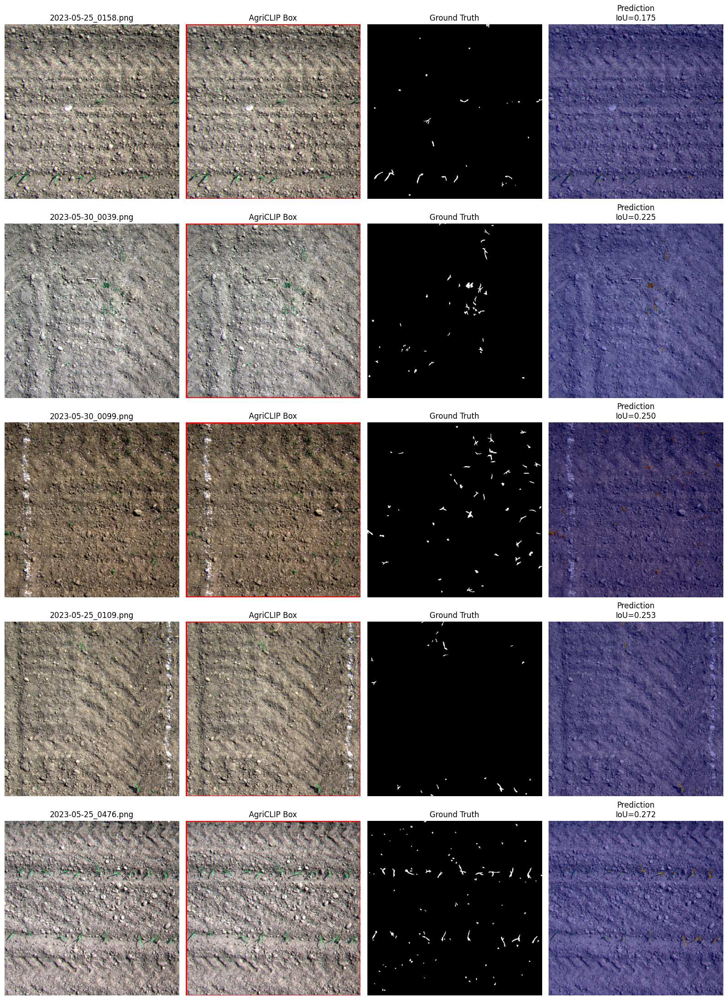

In [49]:
# Visualize the 5 worst WeedsGalore samples

worst_samples = (
    weeds_df
    .sort_values(
        "iou",
        ascending=True
    )
    .head(5)
)

print(
    worst_samples[
        [
            "image_id",
            "file_name",
            "iou",
            "dice",
            "sam2_confidence"
        ]
    ]
)

fig, axes = plt.subplots(
    5,
    4,
    figsize=(16, 22)
)

for row, (_, result) in enumerate(
    worst_samples.iterrows()
):

    idx = int(
        result["image_id"]
    )

    # Load image and GT
    image = get_weeds_image(idx)

    gt_mask = get_weeds_mask(idx)

    # Generate AgriCLIP box again
    (
        agriclip_box,
        boxes,
        scores,
        topk_indices
    ) = generate_agriclip_box(
        image,
        top_k=32,
        margin=25
    )

    # SAM2 prediction
    (
        pred_mask,
        probability,
        confidence
    ) = sam2_predict_box(
        image,
        agriclip_box,
        threshold=0.5
    )

    # -----------------------------------------
    # Input
    # -----------------------------------------

    axes[row, 0].imshow(image)

    axes[row, 0].set_title(
        f"{result['file_name']}"
    )

    axes[row, 0].axis("off")


    # -----------------------------------------
    # AgriCLIP box
    # -----------------------------------------

    axes[row, 1].imshow(image)

    x1, y1, x2, y2 = agriclip_box

    axes[row, 1].add_patch(
        plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        )
    )

    axes[row, 1].set_title(
        "AgriCLIP Box"
    )

    axes[row, 1].axis("off")


    # -----------------------------------------
    # Ground truth
    # -----------------------------------------

    axes[row, 2].imshow(
        gt_mask,
        cmap="gray"
    )

    axes[row, 2].set_title(
        "Ground Truth"
    )

    axes[row, 2].axis("off")


    # -----------------------------------------
    # Prediction + IoU
    # -----------------------------------------

    axes[row, 3].imshow(image)

    axes[row, 3].imshow(
        pred_mask,
        cmap="jet",
        alpha=0.45
    )

    axes[row, 3].set_title(
        f"Prediction\n"
        f"IoU={result['iou']:.3f}"
    )

    axes[row, 3].axis("off")


plt.tight_layout()
plt.show()